<a href="https://colab.research.google.com/github/duyphong110612/bai-2-xaydungmohinh-hoiquytuyentinh/blob/main/B%C3%A0i_" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
BÀI1


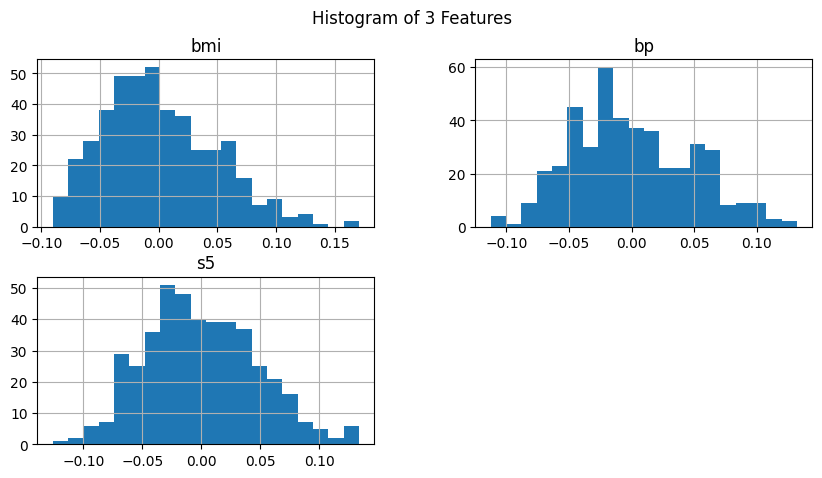

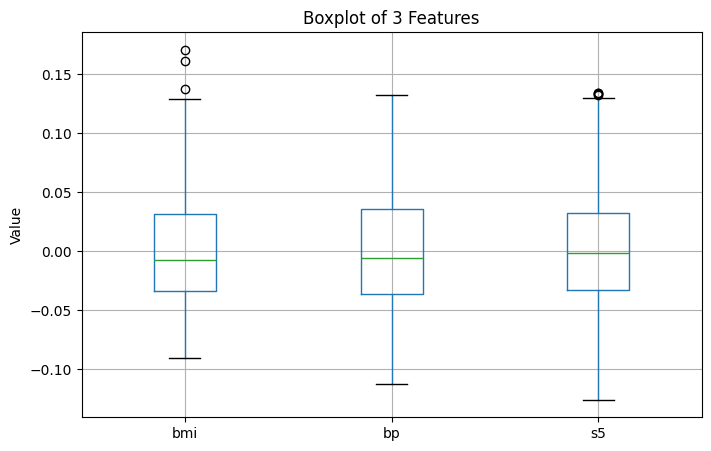

Correlation với target:
bmi    0.586450
bp     0.441482
s5     0.565883
dtype: float64


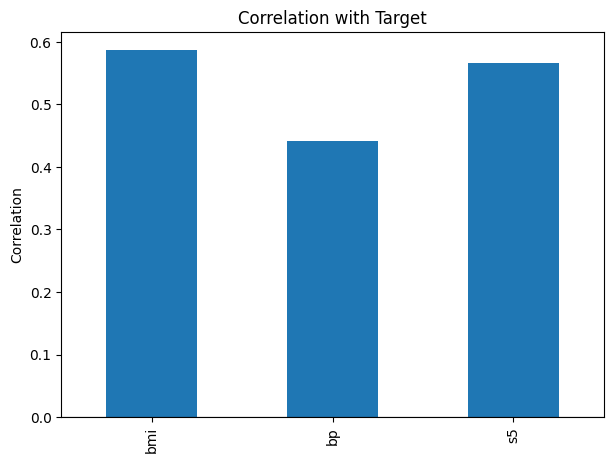

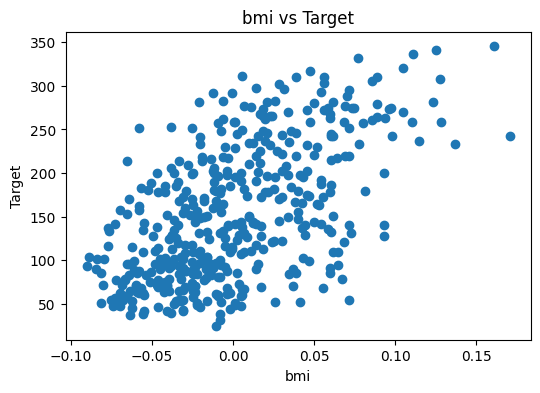

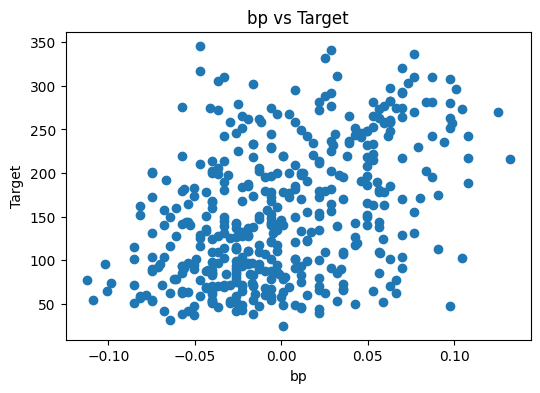

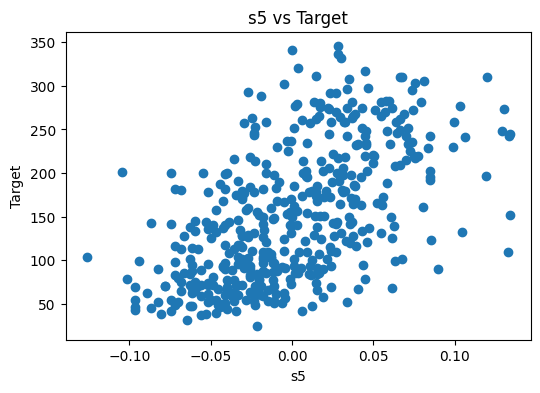

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.datasets import load_diabetes

# 1. Load dữ liệu
diabetes = load_diabetes()

X = pd.DataFrame(diabetes.data, columns=diabetes.feature_names)
y = pd.Series(diabetes.target, name="target")

# Chọn 3 feature
features = ["bmi", "bp", "s5"]

# 2. Histogram
X[features].hist(figsize=(10, 5), bins=20)
plt.suptitle("Histogram of 3 Features")
plt.show()

# 3. Boxplot
plt.figure(figsize=(8, 5))
X[features].boxplot()
plt.title("Boxplot of 3 Features")
plt.ylabel("Value")
plt.show()

# 4. Correlation với target
correlation = X[features].corrwith(y)

print("Correlation với target:")
print(correlation)

correlation.plot(kind="bar", figsize=(7, 5))
plt.title("Correlation with Target")
plt.ylabel("Correlation")
plt.axhline(0, color="black", linewidth=0.8)
plt.show()

# 5. Scatter plot: từng feature với target
for feature in features:
    plt.figure(figsize=(6, 4))
    plt.scatter(X[feature], y)
    plt.xlabel(feature)
    plt.ylabel("Target")
    plt.title(f"{feature} vs Target")
    plt.show()

Nhận xét bài 1: -Phân phối: Các biến bmi, bp, và s5 đều có phân phối xấp xỉ dạng hình chuông (chuẩn/Gaussian), hơi lệch nhẹ về phía bên phải (Right-skewed).

-Ngoại lệ (Outlier):

bmi và s5 xuất hiện một số ít giá trị ngoại lệ nằm ngoài vùng ria (whiskers) của Boxplot.
bp hầu như không có outlier rõ rệt.
Do bộ dữ liệu nhỏ (442 mẫu) và các chỉ số đã chuẩn hóa, ta giữ nguyên các điểm này thay vì loại bỏ.
-Tương quan & Scatter Plot:

Cả 3 biến đều có tương quan dương khá cao với target ( rbmi≈0.58 ,  rs5≈0.56 ,  rbp≈0.44 ).
Scatter plot cho thấy xu hướng phân tán dọc theo đường thẳng tăng dần: khi bmi, bp, s5 tăng thì nguy cơ / chỉ số tiến triển bệnh tiểu đường (target) có xu hướng tăng theo rõ rệt.


BÀI 2


In [ ]:
import pandas as pd
import numpy as np
from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# 1. Tải bộ dữ liệu Diabetes
diabetes = load_diabetes(as_frame=True)
df = diabetes.frame

X = df.drop(columns=['target'])
y = df['target']

# 2. Xกำหนด Top 5 features có độ tương quan tuyệt đối cao nhất với target
correlations = df.corr()['target'].drop('target').abs().sort_values(ascending=False)
top_5_features = correlations.head(5).index.tolist()

print("Top 5 đặc trưng có tương quan cao nhất với biến mục tiêu:", top_5_features)

# 3. Chia tập dữ liệu Train / Test (80% train, 20% test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 4. Định nghĩa các tập đặc trưng (Feature sets)
feature_sets = {
    "Chỉ BMI": ["bmi"],
    "BMI + BP": ["bmi", "bp"],
    "Top 5 Features (Tương quan)": top_5_features,
    "Toàn bộ 10 Features": list(X.columns)
}

# 5. Huấn luyện và đánh giá từng mô hình
results = []

for name, features in feature_sets.items():
    # Khởi tạo và huấn luyện mô hình Hồi quy tuyến tính
    model = LinearRegression()
    model.fit(X_train[features], y_train)

    # Dự đoán trên tập test
    y_pred = model.predict(X_test[features])

    # Tính toán các chỉ số
    mae = mean_absolute_error(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    r2 = r2_score(y_test, y_pred)

    results.append({
        "Bộ đặc trưng": name,
        "Số đặc trưng": len(features),
        "MAE": round(mae, 2),
        "RMSE": round(rmse, 2),
        "R²": round(r2, 4)
    })

# 6. Hiển thị bảng kết quả
results_df = pd.DataFrame(results)
print("\n--- BẢNG SO SÁNH KẾT QUẢ ---")
print(results_df.to_string(index=False))

Top 5 đặc trưng có tương quan cao nhất với biến mục tiêu: ['bmi', 's5', 'bp', 's4', 's3']

--- BẢNG SO SÁNH KẾT QUẢ ---
               Bộ đặc trưng  Số đặc trưng   MAE  RMSE     R²
                    Chỉ BMI             1 52.26 63.73 0.2334
                   BMI + BP             2 50.04 61.16 0.2940
Top 5 Features (Tương quan)             5 43.93 54.19 0.4458
        Toàn bộ 10 Features            10 42.79 53.85 0.4526


BÀI 3


In [ ]:
import numpy as np
import pandas as pd
from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, r2_score

# Các mô hình hồi quy
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.svm import SVR
from sklearn.ensemble import GradientBoostingRegressor

# 1. Tải bộ dữ liệu Diabetes
diabetes = load_diabetes()
X, y = diabetes.data, diabetes.target

# 2. Chia tập dữ liệu thành Train (80%) và Test (20%)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 3. Chuẩn hóa dữ liệu (rất quan trọng đối với Linear, Ridge, SVR)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 4. Khởi tạo các mô hình
models = {
    "Linear Regression": LinearRegression(),
    "Ridge Regression": Ridge(alpha=1.0),
    "Decision Tree Regression": DecisionTreeRegressor(random_state=42),
    "Support Vector Regression (SVR)": SVR(),
    "Gradient Boosting Regression": GradientBoostingRegressor(random_state=42)
}

# 5. Huấn luyện và đánh giá mô hình
results = []

for name, model in models.items():
    # Sử dụng dữ liệu đã chuẩn hóa cho Linear, Ridge, SVR; Tree và Gradient Boosting có thể dùng dữ liệu gốc hoặc chuẩn hóa đều được
    if name in ["Linear Regression", "Ridge Regression", "Support Vector Regression (SVR)"]:
        model.fit(X_train_scaled, y_train)
        y_pred = model.predict(X_test_scaled)
    else:
        model.fit(X_train, y_train)
        y_pred = model.predict(X_test)

    # Tính toán các metric đánh giá
    mse = mean_squared_error(y_test, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, y_pred)

    results.append({
        "Model": name,
        "RMSE": rmse,
        "R2 Score": r2
    })

# 6. Hiển thị kết quả so sánh
results_df = pd.DataFrame(results)
print(results_df.sort_values(by="R2 Score", ascending=False))

                             Model       RMSE  R2 Score
1                 Ridge Regression  53.777454  0.454147
4     Gradient Boosting Regression  53.837131  0.452934
0                Linear Regression  53.853446  0.452603
3  Support Vector Regression (SVR)  65.823540  0.182217
2         Decision Tree Regression  70.546423  0.060654


BÀI 4


In [ ]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.feature_selection import SelectKBest, f_regression

# Các mô hình học máy
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor

# Các chỉ số đánh giá
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Bước 1: Tải bộ dữ liệu
# Đảm bảo bạn đã có file 'kc_house_data.csv' trong môi trường làm việc
df = pd.read_csv('kc_house_data.csv')

print("Kích thước tập dữ liệu:", df.shape)
display(df.head())

# Bước 2: Feature Engineering (Trích xuất đặc trưng mới)
# Chuyển đổi cột 'date' thành dạng năm bán và tính tuổi của nhà tại thời điểm bán
df['date'] = pd.to_datetime(df['date'])
df['sale_year'] = df['date'].dt.year
df['house_age'] = df['sale_year'] - df['yr_built']

# Tạo thêm đặc trưng tổng diện tích phòng (sqft_living + sqft_above + sqft_basement tùy chọn)
df['total_sqft'] = df['sqft_living'] + df['sqft_lot']

# Loại bỏ các cột không cần thiết hoặc định danh cao như 'id', 'date', 'zipcode'
drop_cols = ['id', 'date', 'zipcode', 'sale_year']
df = df.drop(columns=[col for col in drop_cols if col in df.columns])

# Định nghĩa Biến độc lập (X) và Biến mục tiêu (y - giá nhà 'price')
X = df.drop(columns=['price'])
y = df['price']

# Chia tập dữ liệu thành Train (80%) và Test (20%)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Phân loại các cột dạng số (numeric) và dạng phân loại (categorical nếu có)
numeric_features = X.select_dtypes(include=['int64', 'float64']).columns.tolist()
categorical_features = X.select_dtypes(include=['object', 'category']).columns.tolist()

print(f"Số lượng đặc trưng số: {len(numeric_features)}")
print(f"Số lượng đặc trưng phân loại: {len(categorical_features)}")

# Bước 3: Xây dựng bộ tiền xử lý (Preprocessor)
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_features),
        ('cat', categorical_transformer, categorical_features)
    ])

# Bước 4: Định nghĩa danh sách các mô hình cần so sánh
models = {
    "Linear Regression": LinearRegression(),
    "Ridge Regression": Ridge(alpha=1.0),
    "Random Forest": RandomForestRegressor(n_estimators=100, random_state=42),
    "Gradient Boosting": GradientBoostingRegressor(n_estimators=100, random_state=42)
}

# Bước 5: Huấn luyện và đánh giá qua Pipeline
evaluation_results = []

for name, model in models.items():
    # Tạo Pipeline gồm: Tiền xử lý -> Lựa chọn đặc trưng (chọn ra top K đặc trưng tốt nhất) -> Mô hình
    # Ở đây chọn SelectKBest với f_regression để chọn ra K đặc trưng quan trọng nhất (ví dụ k=15 hoặc giữ nguyên tất cả)
    pipeline = Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('feature_selection', SelectKBest(score_func=f_regression, k='all')), # hoặc chọn số lượng k cố định như k=20
        ('model', model)
    ])

    # Huấn luyện mô hình
    pipeline.fit(X_train, y_train)

    # Dự đoán trên tập kiểm tra
    y_pred = pipeline.predict(X_test)

    # Tính toán các chỉ số đánh giá
    mae = mean_absolute_error(y_test, y_pred)
    mse = mean_squared_error(y_test, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, y_pred)

    evaluation_results.append({
        "Model": name,
        "MAE": mae,
        "MSE": mse,
        "RMSE": rmse,
        "R2 Score": r2
    })

# Tổng kết kết quả thành bảng so sánh
results_df = pd.DataFrame(evaluation_results)
results_df = results_df.sort_values(by="R2 Score", ascending=False).reset_index(drop=True)

print("\n--- BẢNG SO SÁNH HIỆU NĂNG CÁC MÔ HÌNH ---")
display(results_df)

Kích thước tập dữ liệu: (21613, 21)


,id,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,...,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15
0,7129300520,20141013T000000,221900.0,3,1.00,1180,5650,1.0,0,0,...,7,1180,0,1955,0,98178,47.5112,-122.257,1340,5650
1,6414100192,20141209T000000,538000.0,3,2.25,2570,7242,2.0,0,0,...,7,2170,400,1951,1991,98125,47.7210,-122.319,1690,7639
2,5631500400,20150225T000000,180000.0,2,1.00,770,10000,1.0,0,0,...,6,770,0,1933,0,98028,47.7379,-122.233,2720,8062
3,2487200875,20141209T000000,604000.0,4,3.00,1960,5000,1.0,0,0,...,7,1050,910,1965,0,98136,47.5208,-122.393,1360,5000
4,1954400510,20150218T000000,510000.0,3,2.00,1680,8080,1.0,0,0,...,8,1680,0,1987,0,98074,47.6168,-122.045,1800,7503


Số lượng đặc trưng số: 19
Số lượng đặc trưng phân loại: 0

--- BẢNG SO SÁNH HIỆU NĂNG CÁC MÔ HÌNH ---


,Model,MAE,MSE,RMSE,R2 Score
0,Random Forest,73212.506662,2.258032e+10,150267.489426,0.850636
1,Gradient Boosting,82500.560590,2.304609e+10,151809.390009,0.847555
2,Linear Regression,127578.567903,4.578655e+10,213977.918775,0.697132
3,Ridge Regression,127602.099110,4.580981e+10,214032.259735,0.696978
